# Approval-time late-delivery prediction

## tl;dr
Logistic regression was selected using validation average precision. On July–August 2018 test approvals, investigating its top 10% identifies 124 of 599 late deliveries from 1,255 investigations (9.88% precision; 20.70% recall). Random ranking would identify approximately 60 late deliveries at the same budget. The fixed validation threshold flags 31.95% of test orders, exposing workload drift. This is a historical portfolio experiment, not a deployed service.

## Context & Methods
Predict late delivery at order approval in historical Brazilian Olist data. Late means the actual delivery calendar date is after the promised calendar date. Compare a constant-prevalence baseline, logistic regression and gradient boosting. PR-AUC uses **average precision**, not trapezoidal integration. Select the model using validation AP, then freeze the model and threshold before testing.

### Key Assumptions
Item, price, freight, product and seller snapshot attributes are assumed available and unchanged at approval; Olist has no attribute version history. No delivery outcomes, reviews, carrier dates or later status enter features. Only delivered orders with observed outcomes are labelled; unresolved/cancelled orders are outside scope. First-item seller state/category represent multi-item orders. Staffing budgets of 5%, 10%, 20% are case-study assumptions.

Train: approvals before January 2018, with delivery labels available before January. Validation: January–June 2018 approvals, labels available before July. Test: July–August 2018 approvals. Purging unavailable labels reduces leakage but may introduce boundary selection bias. Test cohorts may have unequal outcome follow-up.

In [1]:
from pathlib import Path
import sys, io, contextlib, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'python').exists(), 'Run from the project root or notebooks folder'
sys.path.insert(0, str(ROOT / 'python'))
import train_models
print('Features:', ', '.join(train_models.FEATURES))

Features: merchandise_value, freight_value, item_count, seller_count, total_weight_g, max_length_cm, max_height_cm, max_width_cm, promised_days, approval_hour, approval_weekday, same_state, customer_state, seller_state, category_key


## Data
Inputs are generated reproducibly by `python/build_analysis.py` from the nine original CSVs in `data/raw`. SHA-256 source hashes and SQL reconciliation checks are stored in `docs/analysis_checks.json`. The model consumes only the explicit feature whitelist above. `is_late` and actual delivery dates are retained for labels and chronological label-availability purging, never for prediction.

In [2]:
if not (ROOT/'data/processed/model_input.csv').exists():
    import build_analysis
    with contextlib.redirect_stdout(io.StringIO()): build_analysis.main()
source = pd.read_csv(ROOT/'data/processed/model_input.csv')
print(f'{len(source):,} source orders; columns include labels and audit fields as well as features.')
display(source[train_models.FEATURES].head(3).T.rename_axis('Feature'))

99,441 source orders; columns include labels and audit fields as well as features.


,0,1,2
Feature,,,
merchandise_value,29.99,118.7,159.9
freight_value,8.72,22.76,19.22
item_count,1.0,1.0,1.0
seller_count,1.0,1.0,1.0
total_weight_g,500.0,400.0,420.0
max_length_cm,19.0,19.0,24.0
max_height_cm,8.0,13.0,19.0
max_width_cm,13.0,19.0,21.0
promised_days,15.536632,17.858021,26.628206


## Results
### Chronological evaluation
Preprocessing is fitted on training data only. The model with highest validation AP is selected; test outcomes do not select a model or threshold. A model threshold is set to the validation 90th percentile. The constant baseline uses 0.5 and therefore flags no orders; the separate capacity table gives its random-ranking expectation.

In [3]:
with contextlib.redirect_stdout(io.StringIO()):
    metrics, capacity, audit = train_models.main()
display(pd.DataFrame(audit['splits']).T)
print('Selected model:', audit['selected_model'])
display(metrics.round(4))

,orders,late,late_rate,first_approval,last_approval
train,41183,1765,0.042857,2016-09-15 12:16:38,2017-12-28 12:31:55
validation,38622,3389,0.087748,2018-01-01 02:30:25,2018-06-29 12:31:27
test,12545,599,0.047748,2018-07-01 00:10:10,2018-08-29 15:10:26


Selected model: Logistic regression


,model,split,average_precision,precision,recall,investigated,late_found,investigations_per_late,investigation_fraction,threshold
0,Prevalence baseline,validation,0.0877,0.0000,0.0000,0,0,NaN,0.0000,0.5000
1,Prevalence baseline,test,0.0477,0.0000,0.0000,0,0,NaN,0.0000,0.5000
2,Logistic regression,validation,0.1922,0.2392,0.2726,3863,924,4.1807,0.1000,0.0838
3,Logistic regression,test,0.0917,0.0891,0.5960,4008,357,11.2269,0.3195,0.0838
4,Gradient boosting,validation,0.1860,0.2270,0.2588,3863,877,4.4048,0.1000,0.0864
5,Gradient boosting,test,0.0799,0.0769,0.4224,3288,253,12.9960,0.2621,0.0864


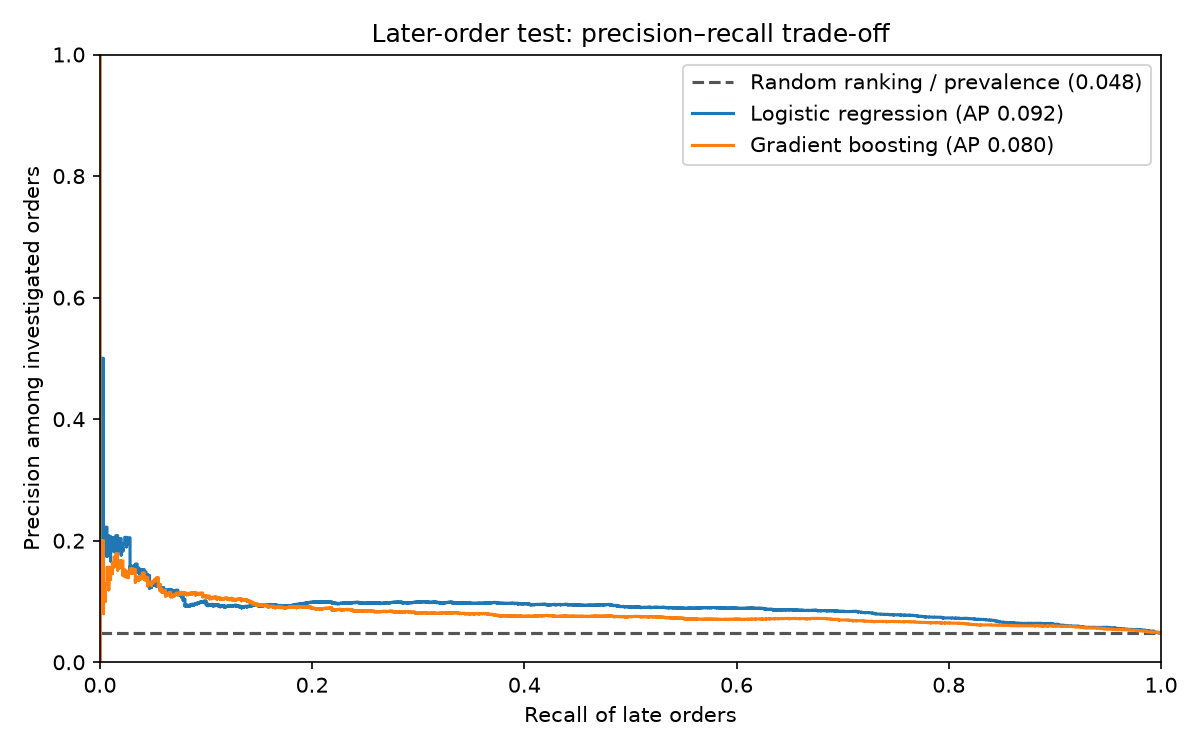

In [4]:
display(Image(filename=str(ROOT/'docs/figures/model_pr.png')))

### Investigation workload
Fixed-budget rankings are retrospective test simulations at predetermined capacities; outcomes are used only to evaluate the ranking. A constant score has no ranking power, so its budget performance is a mathematical random-selection expectation rather than a fabricated observed ranking.

In [5]:
display(capacity.round(4))
chosen = capacity[(capacity.model == audit['selected_model']) & (capacity.budget_fraction == .10)].iloc[0]
print(f"Investigate {int(chosen.investigated):,} orders to find {int(chosen.late_found):,} late orders: {chosen.investigations_per_late:.2f} investigations per late order.")

,model,budget_fraction,investigated,late_found,precision,recall,investigations_per_late,kind
0,Prevalence baseline,0.05,628,29.9858,0.0477,0.0501,20.9432,Random ranking expectation
1,Prevalence baseline,0.10,1255,59.9239,0.0477,0.1000,20.9432,Random ranking expectation
2,Prevalence baseline,0.20,2509,119.8000,0.0477,0.2000,20.9432,Random ranking expectation
3,Logistic regression,0.05,628,60.0000,0.0955,0.1002,10.4667,Observed test ranking
4,Logistic regression,0.10,1255,124.0000,0.0988,0.2070,10.1210,Observed test ranking
5,Logistic regression,0.20,2509,242.0000,0.0965,0.4040,10.3678,Observed test ranking
6,Gradient boosting,0.05,628,66.0000,0.1051,0.1102,9.5152,Observed test ranking
7,Gradient boosting,0.10,1255,114.0000,0.0908,0.1903,11.0088,Observed test ranking
8,Gradient boosting,0.20,2509,203.0000,0.0809,0.3389,12.3596,Observed test ranking


Investigate 1,255 orders to find 124 late orders: 10.12 investigations per late order.


## Takeaways
The selected model improves ranking over random selection but misses most late deliveries at a 10% budget. Its test AP is about 0.092 versus a 0.048 prevalence baseline. Precision remains low: approximately nine of ten flagged orders at that budget are on time. Gradient boosting does not outperform logistic regression on validation AP.

Use the queue as a simulated prioritisation aid, with human investigation and capacity limits. Do not claim reduced delays, saved revenue or deployment readiness. Investigate calibration, temporal drift and route/seller interactions in a new validation period before changing the model; preserve this test set as a final historical evaluation. `docs/model_audit.json` records exclusions and assumptions. `data/processed/historical_priority_queue.csv` is historical, not a live operational queue.